## 1. Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


## 2. Load the dataset

In [3]:
DATA_URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(DATA_URL)
display("Dataset shape:", df.shape)
df.head()


'Dataset shape:'

(20640, 10)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 3. Explore the data and missing values

In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [5]:
df.describe()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [7]:

df.isnull().sum().sort_values(ascending=False)


total_bedrooms        207
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

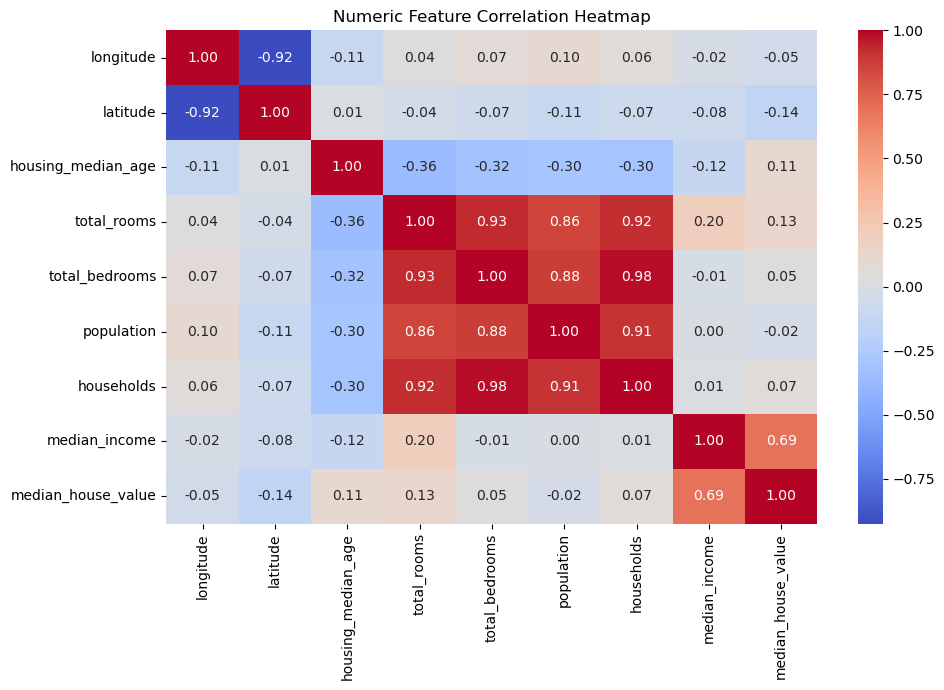

In [8]:
# Correlation heatmap for numeric columns
plt.figure(figsize=(10, 7))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Numeric Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


## 4. Define target and split data

In [9]:
TARGET = "median_house_value"
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])


Training rows: 16512
Testing rows: 4128


## 5. Feature engineering and preprocessing

In [10]:
def add_features(data):
    data = data.copy()
    data["rooms_per_household"] = data["total_rooms"] / (data["households"] + 1e-6)
    data["bedrooms_per_room"] = data["total_bedrooms"] / (data["total_rooms"] + 1e-6)
    data["population_per_household"] = data["population"] / (data["households"] + 1e-6)
    data["income_x_rooms"] = data["median_income"] * data["rooms_per_household"]
    return data

X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)

numeric_features = X_train_fe.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train_fe.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])


## 6. Train OLS, Ridge, and Lasso models

In [11]:
models = {
    "OLS": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(max_iter=20000)
}

results = []
trained_models = {}
for name, model in models.items():
    pipe = Pipeline(steps=[("preprocessing", preprocessor), ("model", model)])
    pipe.fit(X_train_fe, y_train)
    predictions = pipe.predict(X_test_fe)
    results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAE": mean_absolute_error(y_test, predictions),
        "R2": r2_score(y_test, predictions)
    })
    trained_models[name] = pipe

results_df = pd.DataFrame(results).sort_values("RMSE")
results_df


,Model,RMSE,MAE,R2
0,OLS,68917.316717,49709.539512,0.637549
2,Lasso,68918.675789,49710.271495,0.637534
1,Ridge,68925.957233,49715.840794,0.637458


## 7. Tune Ridge and Lasso using GridSearchCV

In [12]:
# Tune regularization strengths (alpha). OLS is kept as the baseline.
alpha_values = [0.01, 0.1, 1, 10, 100]

ridge_pipe = Pipeline(steps=[("preprocessing", preprocessor), ("model", Ridge())])
ridge_grid = GridSearchCV(
    ridge_pipe, {"model__alpha": alpha_values},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1
)
ridge_grid.fit(X_train_fe, y_train)
print("Best Ridge alpha:", ridge_grid.best_params_)
print("Best Ridge CV RMSE:", -ridge_grid.best_score_)

lasso_pipe = Pipeline(steps=[("preprocessing", preprocessor), ("model", Lasso(max_iter=20000))])
lasso_grid = GridSearchCV(
    lasso_pipe, {"model__alpha": alpha_values},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1
)
lasso_grid.fit(X_train_fe, y_train)
print("Best Lasso alpha:", lasso_grid.best_params_)
print("Best Lasso CV RMSE:", -lasso_grid.best_score_)


Best Ridge alpha: {'model__alpha': 1}
Best Ridge CV RMSE: 67759.0287619873
Best Lasso alpha: {'model__alpha': 1}
Best Lasso CV RMSE: 67760.41268271406


## 8. Compare final models on the test set

In [13]:
final_models = {
    "OLS": trained_models["OLS"],
    "Ridge (best)": ridge_grid.best_estimator_,
    "Lasso (best)": lasso_grid.best_estimator_
}
final_results = []
final_predictions = {}
for name, model in final_models.items():
    pred = model.predict(X_test_fe)
    final_predictions[name] = pred
    final_results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred)
    })
final_results_df = pd.DataFrame(final_results).sort_values("RMSE")
final_results_df


,Model,RMSE,MAE,R2
0,OLS,68917.316717,49709.539512,0.637549
2,Lasso (best),68918.675789,49710.271495,0.637534
1,Ridge (best),68925.957233,49715.840794,0.637458


## 9. Actual vs. predicted values

Best model by test RMSE: OLS


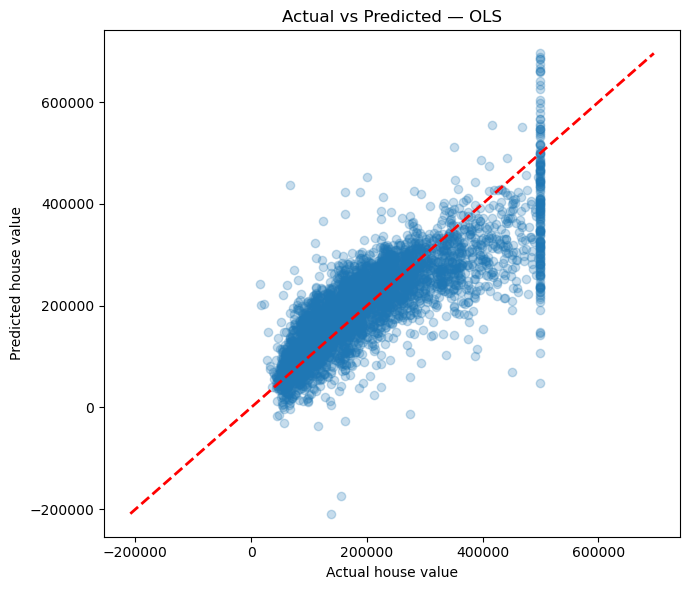

In [14]:
best_name = final_results_df.iloc[0]["Model"]
best_predictions = final_predictions[best_name]
print("Best model by test RMSE:", best_name)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.25)
lims = [min(y_test.min(), best_predictions.min()), max(y_test.max(), best_predictions.max())]
plt.plot(lims, lims, "r--", linewidth=2)
plt.xlabel("Actual house value")
plt.ylabel("Predicted house value")
plt.title(f"Actual vs Predicted — {best_name}")
plt.tight_layout()
plt.show()


## 10. Residual analysis

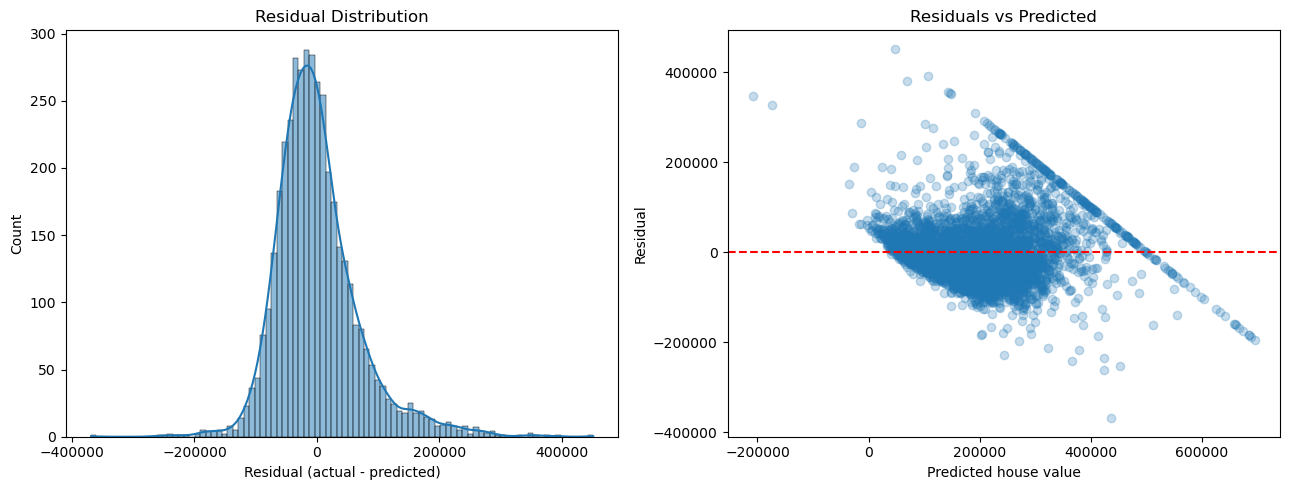

In [15]:
residuals = y_test - best_predictions

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(residuals, kde=True, ax=axes[0])
axes[0].set_title("Residual Distribution")
axes[0].set_xlabel("Residual (actual - predicted)")

axes[1].scatter(best_predictions, residuals, alpha=0.25)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals vs Predicted")
axes[1].set_xlabel("Predicted house value")
axes[1].set_ylabel("Residual")
plt.tight_layout()
plt.show()


## 11. Optional: view a few predictions

In [16]:
prediction_preview = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Predicted": best_predictions[:10],
    "Residual": residuals.iloc[:10].values
})
prediction_preview


,Actual,Predicted,Residual
0,47700.0,33387.911250,14312.088750
1,45800.0,135584.879655,-89784.879655
2,500001.0,289968.553154,210032.446846
3,218600.0,283885.702999,-65285.702999
4,278000.0,263695.454187,14304.545813
5,158700.0,183707.358205,-25007.358205
6,198200.0,278044.961820,-79844.961820
7,157500.0,209578.848829,-52078.848829
8,340000.0,264670.090088,75329.909912
9,446600.0,417947.229020,28652.770980
